# 04b End of Simulation Extreme Frequency Plots

In [1]:
%load_ext autoreload
%autoreload 2
    
import os
import sys
import pandas as pd
import xarray as xr
import numpy as np
from dask.distributed import Client
import warnings
warnings.filterwarnings('ignore')

from cdrmip_extremes import utils, stats, plotting
from cdrmip_extremes.load_processed import load_extremes, load_land_ocean_masks
from cdrmip_extremes.configs import CDR_MODELS, PROC_DIR, FIG_DIR

In [2]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

In [3]:
ext_data = load_extremes(
    PROC_DIR, 'CDRMIP',
    outputs=['exceedances_matching_median_multimodel', 'branch_differences_matching_median_multimodel','agreement_matching'],
    model_order=CDR_MODELS,
)

  sort_models: no order defined for ['multi_model_median'], appending at end
  sort_models: no order defined for ['multi_model_median'], appending at end


In [4]:
exceedances = ext_data['exceedances_matching_median_multimodel']
differences = ext_data['branch_differences_matching_median_multimodel']
agreement = ext_data['agreement_matching']

Saved: /home/563/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S16.jpg


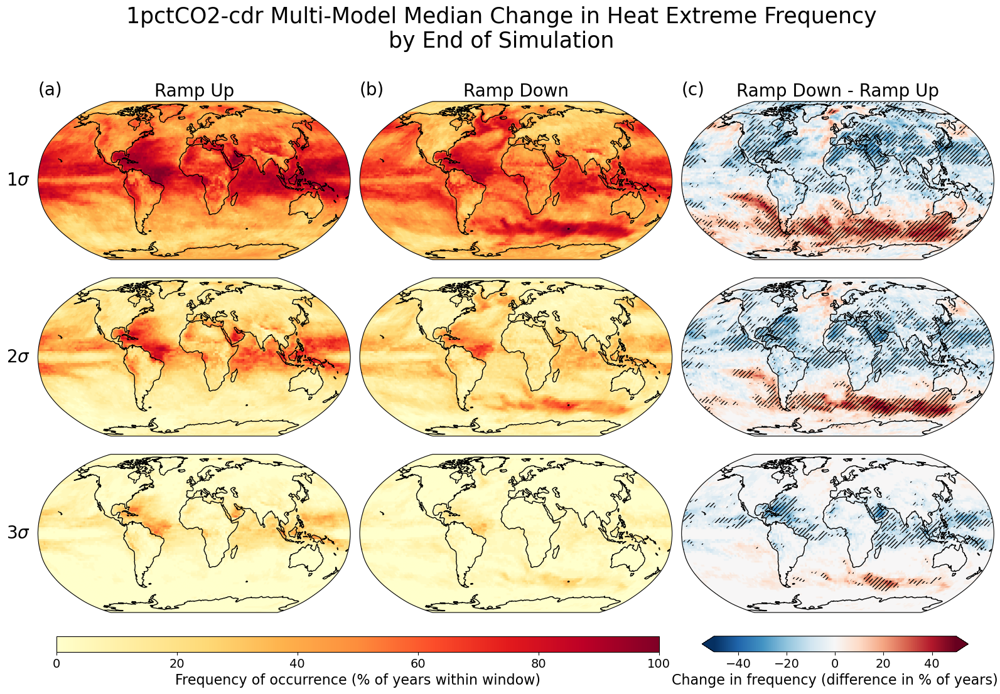

In [5]:
fig = plotting.plot_ext_freq(
    exceedances,
    differences,
    agreement, 
    model='multi_model_median',
    expt='1pctCO2-cdr',
    ext_type='heat',
    gwl=None,
    period='final',
    model_name = 'Multi-Model Median',
    fig_dir=FIG_DIR,
    folder='supplementary',
    file_name='figure_S16.jpg'
    
)

Saved: /home/563/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S17.jpg


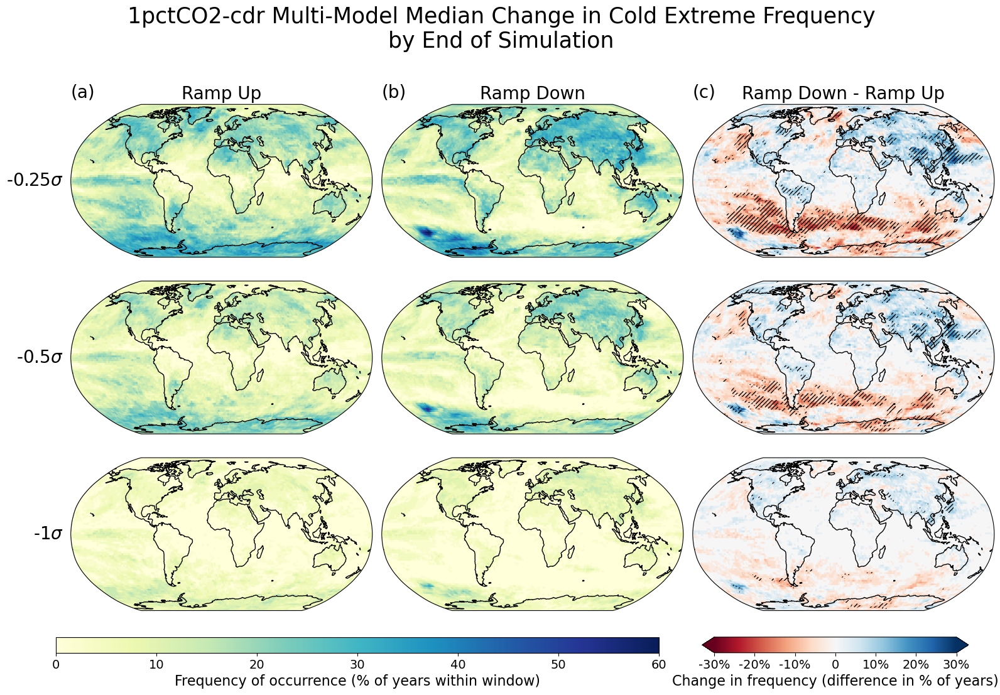

In [6]:
fig = plotting.plot_ext_freq(
    exceedances,
    differences,
    agreement, 
    model='multi_model_median',
    expt='1pctCO2-cdr',
    ext_type='cold',
    gwl=None,
    period='final',
    model_name = 'Multi-Model Median',
    fig_dir=FIG_DIR,
    folder='supplementary',
    file_name='figure_S17.jpg' 
)

## Plot differences for each model

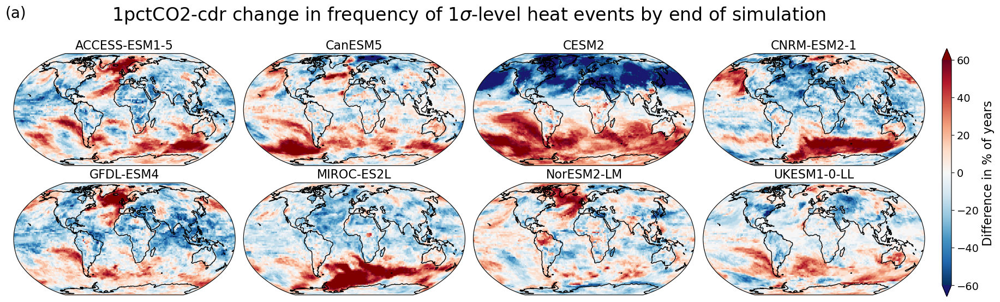

In [9]:
fig = plotting.plot_ext_freq_diff(
    differences=differences,
    expt='1pctCO2-cdr',
    ext_type='heat',
    gwl=None,
    threshold='sigma1',
    levels=None,
    label='(a)',
    title='1$\sigma$',
    period='final',
    vmin=-60,
    vmax=60,
    # fig_dir=FIG_DIR,
    # folder='supplementary',
    # file_name='figure_S4a'
)

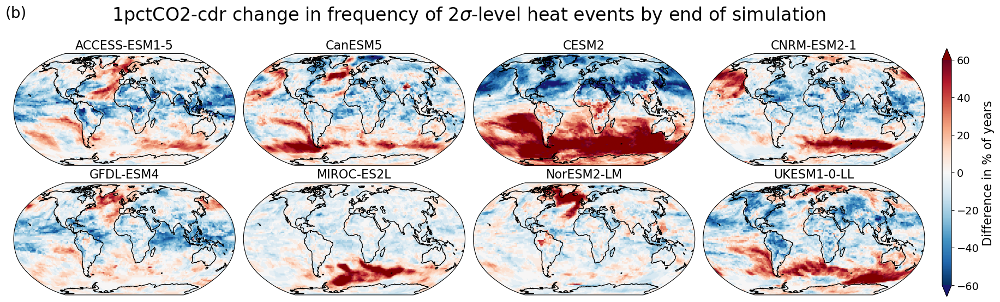

In [10]:
fig = plotting.plot_ext_freq_diff(
    differences=differences,
    expt='1pctCO2-cdr',
    ext_type='heat',
    gwl=None,
    threshold='sigma2',
    levels=None,
    label='(b)',
    title='2$\sigma$',
    period='final',
    vmin=-60,
    vmax=60,
    # fig_dir=FIG_DIR,
    # folder='supplementary',
    # file_name='figure_S4a'
)

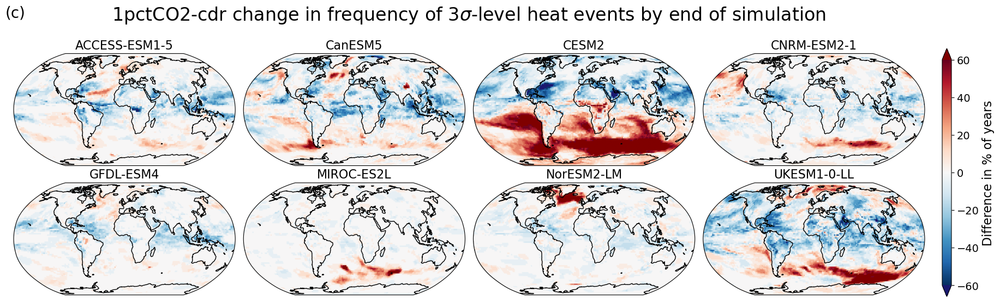

In [11]:
fig = plotting.plot_ext_freq_diff(
    differences=differences,
    expt='1pctCO2-cdr',
    ext_type='heat',
    gwl=None,
    threshold='sigma3',
    levels=None,
    label='(c)',
    title='3$\sigma$',
    period='final',
    vmin=-60,
    vmax=60,
    # fig_dir=FIG_DIR,
    # folder='supplementary',
    # file_name='figure_S4a'
)

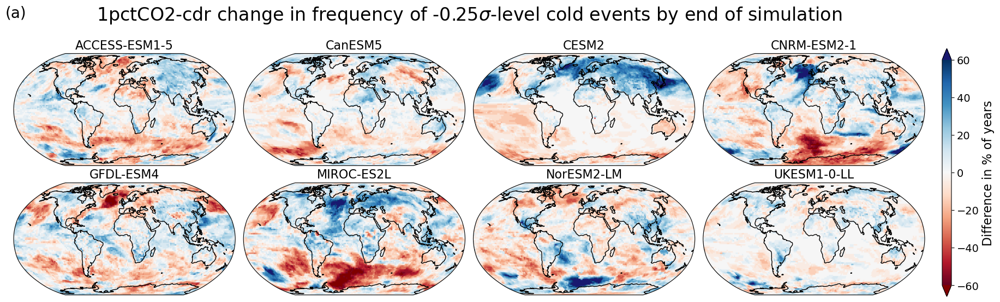

In [14]:
fig = plotting.plot_ext_freq_diff(
    differences=differences,
    expt='1pctCO2-cdr',
    ext_type='cold',
    gwl=None,
    threshold='sigma1',
    levels=None,
    label='(a)',
    title='-0.25$\sigma$',
    period='final',
    vmin=-60,
    vmax=60,
    # fig_dir=FIG_DIR,
    # folder='supplementary',
    # file_name='figure_S4a'
)

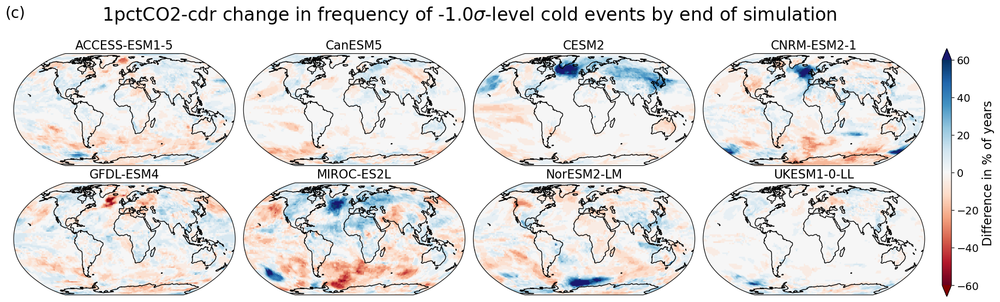

In [12]:
fig = plotting.plot_ext_freq_diff(
    differences=differences,
    expt='1pctCO2-cdr',
    ext_type='cold',
    gwl=None,
    threshold='sigma3',
    levels=None,
    label='(c)',
    title='-1.0$\sigma$',
    period='final',
    vmin=-60,
    vmax=60,
    # fig_dir=FIG_DIR,
    # folder='supplementary',
    # file_name='figure_S4a'
)

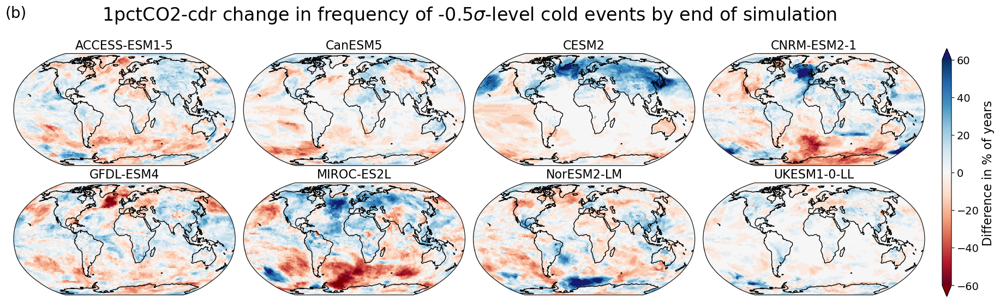

In [13]:
fig = plotting.plot_ext_freq_diff(
    differences=differences,
    expt='1pctCO2-cdr',
    ext_type='cold',
    gwl=None,
    threshold='sigma2',
    levels=None,
    label='(b)',
    title='-0.5$\sigma$',
    period='final',
    vmin=-60,
    vmax=60,
    # fig_dir=FIG_DIR,
    # folder='supplementary',
    # file_name='figure_S4a'
)

## Statistics

In [5]:
from cdrmip_extremes.v2 import regions

In [8]:
land_mask, ocean_mask = load_land_ocean_masks()

Searching for files matching: {'experiment_id': '1pctCO2-cdr', 'source_id': 'ACCESS-ESM1-5', 'member_id': 'r1i1p1f1', 'table_id': 'fx', 'variable_id': ['sftlf']}
Loading ACCESS-ESM1-5 / r1i1p1f1
Building regridder for grid (145,) x (192,)


In [10]:
zonal_subsets_exc = {'cold':{}, 'heat':{}}
for ext_type in ['cold','heat']:
    for model, ds in exceedances.items():
        ds = exceedances[model]['1pctCO2-cdr'][ext_type]
        zonal_subsets_exc[ext_type][model] = {
            'land': regions.get_zonal_subsets(ds,mask=land_mask),
            'ocean': regions.get_zonal_subsets(ds,mask=ocean_mask),
            'all': regions.get_zonal_subsets(ds,mask=None)
        }

In [11]:
zonal_subsets_diff = {'cold':{}, 'heat':{}}
for ext_type in ['cold','heat']:
    for model, ds in differences.items():
        ds = differences[model]['1pctCO2-cdr'][ext_type]
        zonal_subsets_diff[ext_type][model] = {
            'land': regions.get_zonal_subsets(ds,mask=land_mask),
            'ocean': regions.get_zonal_subsets(ds,mask=ocean_mask),
            'all': regions.get_zonal_subsets(ds,mask=None)
        }

In [12]:
zonal_avgs_diff = {'cold':{}, 'heat':{}}
for ext_type in ['cold','heat']:
    for model, ds in differences.items():
        ds = differences[model]['1pctCO2-cdr'][ext_type]
        zonal_avgs_diff[ext_type][model] = {
            'land': regions.get_zonal_averages(ds,mask=land_mask),
            'ocean': regions.get_zonal_averages(ds,mask=ocean_mask),
            'all': regions.get_zonal_averages(ds,mask=None)
        }

In [34]:
zonal_avgs_exc = {'cold':{}, 'heat':{}}
for ext_type in ['cold','heat']:
    for model, ds in exceedances.items():
        ds = differences[model]['1pctCO2-cdr'][ext_type]
        zonal_avgs_exc[ext_type][model] = {
            'land': regions.get_zonal_averages(ds,mask=land_mask),
            'ocean': regions.get_zonal_averages(ds,mask=ocean_mask),
            'all': regions.get_zonal_averages(ds,mask=None)
        }

In [33]:
rows = []
ext_type='heat'
for surface in ['land', 'ocean']:
    zones = zonal_subsets_exc[ext_type]['multi_model_median'][surface]
    for zone, subset in zones.items():
        pct = regions.area_fraction_above(subset.sel(branch='ramp_up'), threshold=33)
        rows.append({
            'surface': surface,
            'zone': zone,
            'sigma1': float(pct.sigma1),
            'sigma2': float(pct.sigma2),
            'sigma3': float(pct.sigma3),
        })

df = pd.DataFrame(rows)
print(df.round(1).to_string(index=False))

surface                zone  sigma1  sigma2  sigma3
   land Southern Hemisphere   100.0    96.2    29.7
   land Northern Hemisphere   100.0    99.8    42.5
   land           Antarctic   100.0    90.1     1.3
   land     SH Extratropics   100.0    97.0     4.5
   land             Tropics   100.0    99.4    56.8
   land     NH Extratropics   100.0   100.0    38.0
   land              Arctic   100.0    99.4    12.2
  ocean Southern Hemisphere   100.0    92.8    31.8
  ocean Northern Hemisphere   100.0    98.0    71.0
  ocean           Antarctic   100.0    52.8     0.9
  ocean     SH Extratropics   100.0    94.0     6.1
  ocean             Tropics   100.0   100.0    74.7
  ocean     NH Extratropics   100.0   100.0    52.9
  ocean              Arctic   100.0    80.8    19.6


In [31]:
ds = exceedances['multi_model_median']['1pctCO2-cdr']['heat'].sel(branch='ramp_down')
pct = regions.area_fraction_above(ds, threshold=4.5)
print(pct.sigma1.values, pct.sigma2.values, pct.sigma3.values)

[100.] [96.07617624] [33.28171483]


In [32]:
ds = exceedances['multi_model_median']['1pctCO2-cdr']['heat'].sel(branch='ramp_up')
pct = regions.area_fraction_above(ds, threshold=4.5)
print(pct.sigma1.values, pct.sigma2.values, pct.sigma3.values)

[100.] [96.07407099] [45.68833665]


In [20]:
2/21

0.09523809523809523

In [43]:
rows = []
for ext_type in ['heat', 'cold']:
    for surface in ['land', 'ocean', 'all']:
        zones = zonal_avgs_diff[ext_type]['multi_model_median'][surface]
        for zone, avg in zones.items():
            rows.append({
                'ext_type': ext_type,
                'surface': surface,
                'zone': zone,
                'sigma1': float(avg.sigma1),
                'sigma2': float(avg.sigma2),
                'sigma3': float(avg.sigma3),
            })

df_avgs = pd.DataFrame(rows)
print(df_avgs.round(2).to_string(index=False))

ext_type surface                zone  sigma1  sigma2  sigma3
    heat    land Southern Hemisphere    1.24   -0.92   -2.49
    heat    land Northern Hemisphere  -12.39  -14.59   -8.73
    heat    land           Antarctic    6.01    5.85    2.47
    heat    land     SH Extratropics    7.20    3.89    1.78
    heat    land             Tropics   -3.49   -7.97   -8.55
    heat    land     NH Extratropics  -17.91  -19.36   -9.36
    heat    land              Arctic  -13.54  -10.67   -2.84
    heat   ocean Southern Hemisphere   11.46   14.21    8.02
    heat   ocean Northern Hemisphere   -5.22   -8.12   -9.24
    heat   ocean           Antarctic    7.38    7.47    2.68
    heat   ocean     SH Extratropics   20.75   26.00   16.70
    heat   ocean             Tropics    0.96   -0.66   -4.89
    heat   ocean     NH Extratropics   -9.64  -11.81   -7.32
    heat   ocean              Arctic   -8.77   -4.77   -1.37
    heat     all Southern Hemisphere    9.54   11.37    6.05
    heat     all Norther